# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers
# TODO: the numbers
#Our baseline window are all the days in September before our surge, giving an accurate view of normal numbers for that time of year
landfall_date = pd.Timestamp('2024-09-26')
baseline_start = pd.Timestamp('2024-09-01')
baseline_end = pd.Timestamp ('2024-09-18')

#Our surge window is one week before the hurricane hit on the 26th
surge_start = pd.Timestamp('2024-09-19')
surge_end = pd.Timestamp('2024-09-25')

baseline = daily_orders[daily_orders['date'].between(baseline_start, baseline_end)]
surge = daily_orders[daily_orders['date'].between(surge_start, surge_end)]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

multiple = surge_avg / baseline_avg

print(f'Hurricane Helene landfall: {landfall_date.date()}')
print(f'Baseline window: {baseline_start} to {baseline_end}')
print(f'Surge window: {surge_start} to {surge_end}')
print(f'Baseline average: {baseline_avg:.2f}')
print(f'Surge average: {surge_avg:.2f}')
print(f'Multiple: {multiple:.2f}')

In [ ]:
# Create a complete daily series so dates with no transactions count as zero
daily_units = (
    transactions.dropna(subset=['date_best'])
    .groupby('date_best')['quantity_clean']
    .sum()
    .reindex(pd.date_range('2024-09-01', '2024-09-30'), fill_value=0)
    .rename_axis('date')
    .reset_index(name='units')
)

baseline = daily_units[
    daily_units['date'].between(baseline_start, baseline_end)
]

surge = daily_units[
    daily_units['date'].between(surge_start, surge_end)
]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

surge_multiple = surge_avg / baseline_avg if baseline_avg else np.nan
percent_increase = (
    ((surge_avg - baseline_avg) / baseline_avg) * 100
    if baseline_avg else np.nan
)

print(f'\nBaseline average daily units: {baseline_avg:.2f}')
print(f'Surge average daily units: {surge_avg:.2f}')
print(f'Surge multiple: {surge_multiple:.2f}x')
print(f'Percentage increase: {percent_increase:.2f}%')

In [ ]:
# category-level daily avgs for both windows
dated_transactions = transactions.dropna(subset=['date_best']).copy()
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div(7)
)

# baseline contains 18 days, while the surge contains 7 days.
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((baseline_end - baseline_start).days + 1)
)

surge_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            surge_start, surge_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((surge_end - surge_start).days + 1)
)

category_comparison = pd.concat(
    [
        baseline_category.rename('baseline_avg_daily_units'),
        surge_category.rename('surge_avg_daily_units')
    ],
    axis=1
).fillna(0)

category_comparison['unit_change'] = (
    category_comparison['surge_avg_daily_units']
    - category_comparison['baseline_avg_daily_units']
)

category_comparison['percent_increase'] = np.where(
    category_comparison['baseline_avg_daily_units'] > 0,
    category_comparison['unit_change']
    / category_comparison['baseline_avg_daily_units'] * 100,
    np.nan
)

category_comparison = category_comparison.sort_values(
    'surge_avg_daily_units', ascending=False
)

print('\nCategory comparison:')
display(category_comparison.round(2))

In [ ]:
# Top five categories by average daily units during the surge
top_five_categories = category_comparison.head(5)

print('\nTop five categories during the surge:')
display(top_five_categories.round(2))


Top five categories during the surge:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59


In [ ]:
# TODO: the chart
# Daily sales trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_units['date'],
    daily_units['units'],
    marker='o',
    label='Daily units sold'
)

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.2, color='blue', label='Baseline'
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.2, color='red', label='7-day surge window'
)

plt.axvline(
    landfall_date,
    linestyle='--',
    color='black',
    label='Helene landfall (Sept. 26)'
)

plt.title('Daily Walmart Unit Sales Before Hurricane Helene Landfall')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Category comparison chart
category_comparison[
    ['baseline_avg_daily_units', 'surge_avg_daily_units']
].plot(kind='bar', figsize=(12, 5))

plt.title('Average Daily Units by Category: Baseline vs. Surge')
plt.xlabel('Category')
plt.ylabel('Average Daily Units')
plt.xticks(rotation=45, ha='right')
plt.legend(['Baseline', 'Surge'])
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** _..._

In [ ]:
print(
    f"Average daily unit sales increased from {baseline_avg:.0f} "
    f"units during the baseline period to {surge_avg:.0f} units in "
    f"the seven days before landfall, a {surge_multiple:.2f}x increase."
)

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
# TODO
#Counting distinct sku and distinct products
raw_skus = transactions['sku'].nunique()
canon_products = transactions['canonical_sku'].nunique()
#Determining how many SKU belong to each canonical product
family_size = products.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

largest_fam = family_size.index[0]
largest_size = family_size.iloc[0]

print('Distinct raw:', raw_skus)
print('Canonical products:', canon_products)
print('Largest consolidated family:', largest_fam)
print('Family size:', largest_size)

#Making sure thatnothing changed in total units ater consolidation
before_units = transactions['quantity_clean'].sum()
after_units = (transactions.groupby('canonical_sku')['quantity_clean'].sum().sum())

print(f"Units before consolidation: {before_units}")
print(f"Units after consolidation:  {after_units}")
print(f"Totals were preserved? {before_units == after_units}")

In [ ]:
top_fams = family_size.head(10)

plt.figure(figsize=(12, 5))
top_fams.plot(kind='bar')
plt.title('Top 10 Canonical Products by SKUs')
plt.xlabel('Canonical Product')
plt.ylabel('Number of SKUs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Select all transactions belonging to the Pop-Tarts family
poptarts = transactions[
    transactions['canonical_sku'] == 'POPTART-STRAW'
].dropna(subset=['date_best']).copy()

print('Pop-Tarts raw SKU variants:')
display(
    poptarts.groupby('sku')['quantity_clean']
    .agg(['count', 'sum'])
    .rename(columns={
        'count': 'transaction_count',
        'sum': 'total_units'
    })
    .sort_values('total_units', ascending=False)
)

# Fragmented: daily units for each original SKU
fragmented_daily = (
    poptarts.groupby(['date_best', 'sku'])['quantity_clean']
    .sum()
    .unstack(fill_value=0)
)

# Consolidated: daily units across all Pop-Tarts SKUs
consolidated_daily = (
    poptarts.groupby('date_best')['quantity_clean']
    .sum()
    .rename('Pop-Tarts total')
)

# index both views to the full month
full_dates = pd.date_range('2024-09-01', '2024-09-30')

fragmented_daily = fragmented_daily.reindex(
    full_dates, fill_value=0
)

consolidated_daily = consolidated_daily.reindex(
    full_dates, fill_value=0
)

# Compare total units to verify consolidation preserves volume
fragmented_total = fragmented_daily.to_numpy().sum()
consolidated_total = consolidated_daily.sum()

print(f'Fragmented total units: {fragmented_total:,.0f}')
print(f'Consolidated total units: {consolidated_total:,.0f}')
print(
    'Totals preserved:',
    np.isclose(fragmented_total, consolidated_total)
)

# Side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

fragmented_daily.plot(
    kind='line',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Pop-Tarts Sales by Raw SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units Sold')
axes[0].legend(title='Raw SKU', fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(
    consolidated_daily.index,
    consolidated_daily.values,
    marker='o',
    label='All Pop-Tarts SKUs'
)

axes[1].set_title('Consolidated Pop-Tarts Daily Sales')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Units Sold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Fragmented vs. Consolidated Pop-Tarts Sales')
plt.tight_layout()
plt.show()

# Calculate consolidated volume for the largest raw SKU
raw_sku_totals = poptarts.groupby('sku')['quantity_clean'].sum()

largest_sku_units = raw_sku_totals.max()
largest_sku_share = (
    largest_sku_units / consolidated_total * 100
    if consolidated_total else np.nan
)

print(f'Largest individual SKU: {raw_sku_totals.idxmax()}')
print(f'Units under that SKU: {largest_sku_units:,.0f}')
print(f'Share of consolidated Pop-Tarts volume: {largest_sku_share:.2f}%')

**Q2 answer:** _..._

In [ ]:
print(
    f"SKU consolidation reduced {raw_skus} transaction SKUs into "
    f"{canon_products} canonical products. The largest family "
    f"was {largest_fam} with {largest_size} SKU variants, and "
    f"unit totals were unchanged after consolidation."
)

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO
#First I'm making sure the join worked
#Rows before merge
sales_before = len(daily_orders)

#Rows after merger
sales_after = len(orders_weather)

print(f'Rows before join: {sales_before}')
print(f'Rows after join:  {sales_after}')
print(f'Rows preserved? {sales_before== sales_after}')

#Where weather is coming from
weather_source = weather_daily['source'].iloc[0]
print(f'Weather source: {weather_source}')

#Seeing how many days will be analyzed in the correlation
n_days = len(orders_weather)

print(f'Days includes:{n_days}')

#Calculating correlations; dont have pressure input yet
corr_precip = orders_weather['units'].corr(orders_weather['precipitation_sum'])
corr_wind = orders_weather['units'].corr(orders_weather['windspeed_10m_max'])
#corr_pressure = orders_weather['units'].corr(orders_weather['pressure_msl'] )

print(f'Correlation with precipitation: {corr_precip:.3f}')
print(f'Correlation with wind: {corr_wind:.3f}')
#print(f'Correlation with pressure: {corr_pressure:.3f}')

#Finding the strongest correlations
correlations = {
    'Precipitation': corr_precip,
    'Wind': corr_wind,
    #'Pressure': corr_pressure#
}

strongest_var = max(correlations, key=lambda k: abs(correlations[k]))
strongest_corr = correlations[strongest_var]
print(f'Strongest relationship: {strongest_var} with 'f'a correlation of {strongest_corr:.3f}')


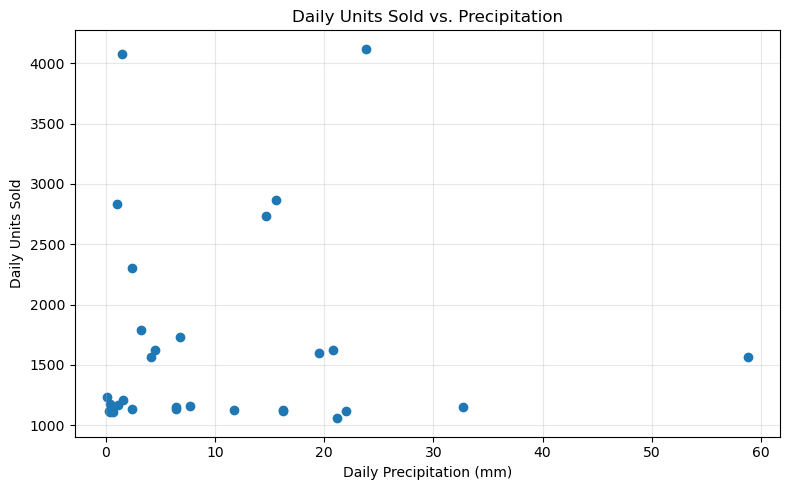

In [ ]:
plt.figure(figsize =(8,5))
plt.scatter(orders_weather['precipitation_sum'],orders_weather['units'])

plt.title('Daily Units Sold vs. Precipitation')
plt.xlabel('Daily Precipitation (mm)')
plt.ylabel('Daily Units Sold')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _The join is done, just need to do comparisons and charts. Anya is going to finish this over the week_

**Q5 (signal or artifact):** _Haven't started. Anya is going to finish this over the week_

### Self-check

In [ ]:
progress = {
    'q1_multiple': round(multiple,2),            # TODO: a number
    'q1_baseline_window': 'September 1st through 18th',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': '30', # TODO: a number
    'charts_with_message_titles': 'Three',  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a. We were suprised by the surge in unit sales on the 13th and 14th which fall before the surge window and are much higher than any values in the surge window. To make sure this wasn't a bug we checked that the transactions totals stayed the same, andthat the weather join didn't create any duplicates or lose any rows.

b. We are least confidant in the Q1 surge multiple because it depends on how the baseline and surge are framed and since there is a spike in the baseline period, there is more uncertainty around this figure.